# Crear estado inicial para pp_set

Este notebook construye la matriz `actual_state` con la que arranca `PP_set` y la guarda como
`Init_data/init_state_{i}.npz`, **sustituyendo** la que genera `python -m RRAM init`.

## Flujo de trabajo

1. En `Lanzar_simulacion_RRAM.ipynb`: ejecutar la generación de CSV (celda 9) y el INIT (celda 12). Eso deja `Init_data/` con los CSV y un `init_state_{i}.npz` aleatorio por simulación.
2. **Este notebook**: sobrescribe los `init_state_{i}.npz` que quieras con tu distribución.
3. En `Lanzar_simulacion_RRAM.ipynb`: ejecutar EXEC (celda 14) **sin volver a lanzar el INIT**, o se pierde el estado.

## Qué se guarda

| Archivo | Clave | Forma | Tipo |
|---------|-------|-------|------|
| `Init_data/init_state_{i}.npz` | `actual_state` | `(eje_x, eje_y)` | `int` (0 = óxido, 1 = vacante) |

`eje_x = params.y_size` (filas) y `eje_y = params.x_size` (columnas, dirección de la corriente).

> Antes de sobrescribir se copia el estado original en `Init_data/backup_init_aleatorio/`
> (solo la primera vez, para no pisar la copia con un estado ya editado).

In [53]:
import math
import shutil
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import convolve2d

from matplotlib.colors import ListedColormap
from RRAM import Percolation, utils
from RRAM.Representate import config_ax_state, setup_paper_plt
from RRAM.init_simulation import load_simulation_config

## 1 · Configuración

In [54]:
# ── Ajusta estos valores ──────────────────────────────────────────────────
INIT_DATA_DIR = Path("Init_data")

# Simulaciones a procesar (índices 0-based del CSV). None → todas las del CSV.
SIMULACIONES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]          # None | [0, 3, 5]

# Semilla para el sorteo de trampas. None → aleatorio real.
# Con MISMO_ESTADO=True todas las sims usan SEED; con False, SEED + i.
SEED = 42
MISMO_ESTADO = False

# True → guarda los .npz. False → solo genera y visualiza (ensayo en seco).
GUARDAR = True

# ── Distribución del estado inicial ──────────────────────────────────────
# DISTRIBUCION: "uniforme" → vacantes completamente aleatorias en toda la matriz
#               "parejas"  → franja del filamento con parejas + resto uniforme
DISTRIBUCION = "uniforme"

# Parámetros de "parejas". Valores PROVISIONALES: ajústalos al modelo que quieras.
# Peso de sorteo de la franja del filamento frente al resto de la matriz (=1).
# Antes era 70 (muy concentrado); más bajo = resto más uniforme.
PESO_CENTRO = 5
# Probabilidad de que una vacante sorteada forme pareja con una vecina libre,
# según caiga dentro o fuera de la franja del filamento.
P_PAREJA_CENTRO = 0.9
P_PAREJA_FUERA = 0.001
# ─────────────────────────────────────────────────────────────────────────

if SIMULACIONES is None:
    n_sims = sum(1 for _ in open(INIT_DATA_DIR / "simulation_parameters.csv")) - 1
    SIMULACIONES = list(range(n_sims))
print(f"Simulaciones a procesar: {SIMULACIONES}")
print(f"Guardar en disco: {GUARDAR}")

Simulaciones a procesar: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Guardar en disco: True


## 2 · Funciones de generación

Copias de las que usa la simulación (`utils.generar_configuracion_filamentos` y
`Generation.initial_state_priv`). Están duplicadas aquí a propósito para poder adaptarlas
sin tocar el simulador. Con `construir_estado_inicial` tal cual está, el resultado es el
mismo tipo de estado que produce `init`.

In [55]:
def generar_configuracion_filamentos(
    eje_x: int,
    eje_y: int,
    num_filamentos: int,
    peso_central: int = 70,
    grosores_filamento: list | int | None = None,
    centros_override: list[int] | None = None,
) -> tuple:
    """Copia de utils.generar_configuracion_filamentos: rangos, regiones de peso y centros."""
    if grosores_filamento is None:
        grosores = [2] * num_filamentos
    elif isinstance(grosores_filamento, (int, np.integer)):
        grosores = [int(grosores_filamento)] * num_filamentos
    else:
        grosores_raw = list(grosores_filamento)
        if len(grosores_raw) < num_filamentos:
            grosores_raw += [grosores_raw[-1]] * (num_filamentos - len(grosores_raw))
        grosores = [int(g) for g in grosores_raw[:num_filamentos]]

    usar_override = isinstance(centros_override, list) and len(centros_override) > 0

    filamentos_ranges = []
    regiones_pesos = []
    filas_centrales = []

    ancho_zona = eje_x // num_filamentos

    for n in range(num_filamentos):
        inicio_rango = n * ancho_zona
        fin_rango = (n + 1) * ancho_zona - 1 if n < num_filamentos - 1 else eje_x - 1
        filamentos_ranges.append((inicio_rango, fin_rango))

        if usar_override:
            fila_central = int(centros_override[n])
            if not (inicio_rango <= fila_central <= fin_rango):
                raise ValueError(f"centros_override[{n}]={fila_central} fuera de rango [{inicio_rango}, {fin_rango}]")
        else:
            fila_central = (inicio_rango + fin_rango) // 2
        filas_centrales.append(fila_central)

        grosor = grosores[n]
        x_start = max(0, fila_central - grosor)
        x_end = min(eje_x, fila_central + grosor + 1)

        regiones_pesos.append(((x_start, x_end, 0, eje_y), peso_central))

    return filamentos_ranges, regiones_pesos, filas_centrales


def initial_state_priv(eje_x: int, eje_y: int, num_trampas: int, regiones_pesos: list) -> np.ndarray:
    """Copia de Generation.initial_state_priv: sortea `num_trampas` vacantes con pesos por región."""
    estado = np.zeros((eje_x, eje_y), dtype=int)

    pesos = np.ones((eje_x, eje_y), dtype=float)
    for (x_start, x_end, y_start, y_end), peso in regiones_pesos:
        pesos[x_start:x_end, y_start:y_end] = peso
    pesos_flat = pesos.flatten()

    posiciones = np.random.choice(eje_x * eje_y, num_trampas, replace=False, p=pesos_flat / np.sum(pesos_flat))
    for pos in posiciones:
        fila, columna = divmod(pos, eje_y)
        estado[fila, columna] = 1

    return estado

## 3 · Tu distribución inicial

`construir_estado_inicial` recibe la configuración de la simulación y devuelve la matriz.

Se elige con `DISTRIBUCION` en la celda de configuración:

- `"uniforme"` (`initial_state_uniforme`): `num_trampas` vacantes en celdas distintas elegidas al azar con la misma probabilidad en toda la matriz. Sin franja de filamento ni parejas.
- `"parejas"` (`initial_state_parejas`):
- Las vacantes se sortean una a una con pesos: `PESO_CENTRO` en la franja del filamento (misma
  región que antes, `centro ± grosor`) y 1 en el resto, de modo que fuera de la franja la
  distribución es uniforme.
- Cada vacante sorteada forma **pareja** con una vecina libre (arriba, abajo, izquierda o derecha,
  orientación aleatoria) con probabilidad `P_PAREJA_CENTRO` si cae en la franja, o
  `P_PAREJA_FUERA` si cae fuera. Así las parejas son mucho más probables en el centro y fuera
  predominan las vacantes aisladas.
- El total de vacantes es siempre `num_trampas`.

Si cambias el número de vacantes, actualiza `num_trampas` en el barrido de la celda 9 del
notebook principal para que el CSV siga coherente con `estado.sum()`.

In [56]:
def initial_state_uniforme(eje_x: int, eje_y: int, num_trampas: int) -> np.ndarray:
    """Coloca `num_trampas` vacantes en celdas distintas elegidas al azar, con igual probabilidad en toda la matriz."""
    estado = np.zeros(eje_x * eje_y, dtype=int)
    estado[np.random.choice(eje_x * eje_y, num_trampas, replace=False)] = 1
    return estado.reshape(eje_x, eje_y)

In [57]:
VECINOS_CRUZ = [(-1, 0), (1, 0), (0, -1), (0, 1)]


def initial_state_parejas(
    eje_x: int,
    eje_y: int,
    num_trampas: int,
    regiones_pesos: list,
    p_pareja_centro: float,
    p_pareja_fuera: float,
) -> np.ndarray:
    """Sortea `num_trampas` vacantes con pesos por región; algunas se colocan por parejas.

    Cada iteración sortea una celda libre con probabilidad proporcional a su peso. Si cae en
    una región de `regiones_pesos` forma pareja con prob. `p_pareja_centro`, si no con
    `p_pareja_fuera`. La pareja ocupa además una vecina libre elegida al azar (cruz, sin
    diagonales); si no hay ninguna libre, o solo queda una vacante por colocar, va suelta.
    """
    estado = np.zeros((eje_x, eje_y), dtype=int)

    pesos = np.ones((eje_x, eje_y), dtype=float)
    zona = np.zeros((eje_x, eje_y), dtype=bool)
    for (x_start, x_end, y_start, y_end), peso in regiones_pesos:
        pesos[x_start:x_end, y_start:y_end] = peso
        zona[x_start:x_end, y_start:y_end] = True

    colocadas = 0
    while colocadas < num_trampas:
        p = np.where(estado == 0, pesos, 0.0).ravel()
        fila, columna = divmod(np.random.choice(eje_x * eje_y, p=p / p.sum()), eje_y)
        estado[fila, columna] = 1
        colocadas += 1

        p_pareja = p_pareja_centro if zona[fila, columna] else p_pareja_fuera
        if colocadas < num_trampas and np.random.random() < p_pareja:
            libres = [
                (fila + df, columna + dc)
                for df, dc in VECINOS_CRUZ
                if 0 <= fila + df < eje_x and 0 <= columna + dc < eje_y and estado[fila + df, columna + dc] == 0
            ]
            if libres:
                f2, c2 = libres[np.random.randint(len(libres))]
                estado[f2, c2] = 1
                colocadas += 1

    return estado

In [58]:
def construir_estado_inicial(cfg, eje_x: int, eje_y: int) -> np.ndarray:
    """Devuelve la matriz (eje_x, eje_y) de 0/1 con la que arrancará PP_set."""
    if DISTRIBUCION == "uniforme":
        estado = initial_state_uniforme(eje_x, eje_y, cfg.num_trampas)
    elif DISTRIBUCION == "parejas":
        sim_ctes = cfg.sim_ctes

        # Mismo criterio que build_initial_states: grosor_filamento_init, si existe, manda
        # solo para el sorteo inicial.
        grosor_init = getattr(sim_ctes, "grosor_filamento_init", None)
        grosor = grosor_init if grosor_init is not None else sim_ctes.grosor_filamento

        _, regiones_pesos, _ = generar_configuracion_filamentos(
            eje_x,
            eje_y,
            num_filamentos=sim_ctes.num_filamentos,
            peso_central=PESO_CENTRO,
            grosores_filamento=grosor,
            centros_override=sim_ctes.centros_filamento,
        )

        estado = initial_state_parejas(
            eje_x, eje_y, cfg.num_trampas, regiones_pesos, P_PAREJA_CENTRO, P_PAREJA_FUERA
        )
    else:
        raise ValueError(f"DISTRIBUCION desconocida: {DISTRIBUCION!r} (usa 'uniforme' o 'parejas')")

    # ── ADAPTAR AQUÍ ──────────────────────────────────────────────────────
    # Ejemplos:
    #   estado[40:60, 10:20] = 1          # bloque de vacantes
    #   estado = np.load("mi_matriz.npy") # matriz propia
    # ──────────────────────────────────────────────────────────────────────
    return estado.astype(int)


## 4 · Comprobaciones y guardado

Para cada simulación: carga su configuración, genera el estado, comprueba forma y número de
trampas contra el CSV, y (si `GUARDAR=True`) hace copia de seguridad y sobrescribe el `.npz`.

In [59]:
def comprobar_estado(estado: np.ndarray, cfg, eje_x: int, eje_y: int) -> None:
    """Avisa si la matriz no es compatible con lo que el CSV espera."""
    if estado.shape != (eje_x, eje_y):
        raise ValueError(f"Forma {estado.shape} distinta de la esperada {(eje_x, eje_y)}")
    if not np.isin(estado, (0, 1)).all():
        raise ValueError("El estado solo puede contener 0 y 1")
    if int(estado.sum()) != cfg.num_trampas:
        print(f"  ⚠ vacantes={int(estado.sum())} ≠ num_trampas del CSV={cfg.num_trampas}. "
              f"Actualiza num_trampas en el barrido del notebook principal.")


def guardar_estado(estado: np.ndarray, num_simulation: int) -> Path:
    destino = INIT_DATA_DIR / f"init_state_{num_simulation}.npz"
    backup_dir = INIT_DATA_DIR / "backup_init_aleatorio"
    backup = backup_dir / destino.name
    if destino.is_file() and not backup.is_file():
        backup_dir.mkdir(exist_ok=True)
        shutil.copy2(destino, backup)
    np.savez_compressed(destino, actual_state=estado)
    return destino


estados = {}
for i in SIMULACIONES:
    cfg = load_simulation_config(num_simulation=i, init_data_dir=INIT_DATA_DIR)
    eje_x, eje_y = cfg.params.y_size, cfg.params.x_size

    if SEED is not None:
        np.random.seed(SEED if MISMO_ESTADO else SEED + i)

    estado = construir_estado_inicial(cfg, eje_x, eje_y)
    print(f"Sim {i}: shape={estado.shape} vacantes={int(estado.sum())} / {estado.size}")
    comprobar_estado(estado, cfg, eje_x, eje_y)
    estados[i] = estado

    if GUARDAR:
        print(f"  guardado → {guardar_estado(estado, i)}")

if not GUARDAR:
    print("\nEnsayo en seco: no se ha escrito nada. Pon GUARDAR=True para sobrescribir.")

Sim 0: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_0.npz
Sim 1: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_1.npz
Sim 2: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_2.npz
Sim 3: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_3.npz
Sim 4: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_4.npz
Sim 5: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_5.npz
Sim 6: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_6.npz
Sim 7: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_7.npz
Sim 8: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_8.npz
Sim 9: shape=(120, 40) vacantes=250 / 4800
  guardado → Init_data/init_state_9.npz


## 5 · Visualizar

Mismo estilo que `Representate.RepresentateState` (colores, ejes en nm, electrodos grises, ticks
hacia dentro). `RepresentateState` guarda a disco y cierra la figura, así que aquí se reutiliza
su estilo sobre ejes propios con `dibujar_estado`.


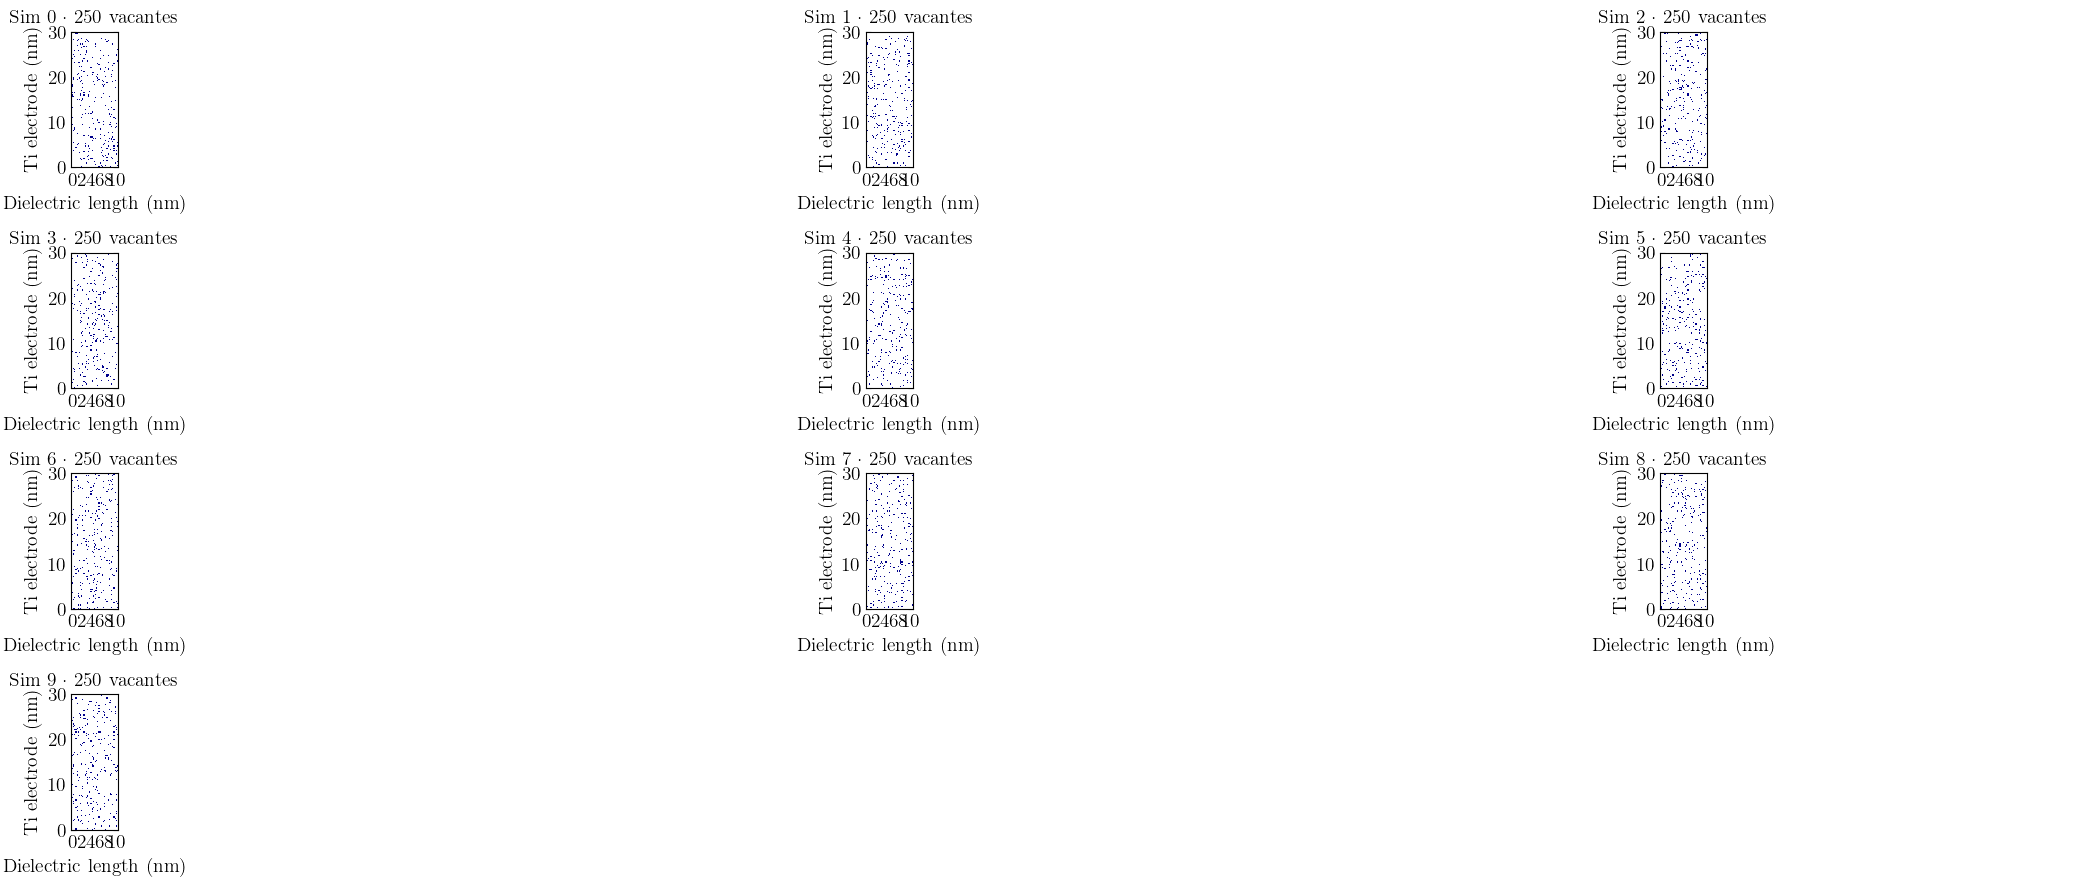

In [66]:
COLOR_VACANTE = (0.0000, 0.0000, 0.5451)  # mismo que RepresentateState


def dibujar_estado(ax, matriz: np.ndarray, atom_size: float) -> tuple[float, float]:
    """Pinta `matriz` en `ax` con el estilo de Representate.RepresentateState.

    Ejes en nm, origen abajo, electrodos grises a ambos lados y ticks automáticos.
    Devuelve (size_x_nm, size_y_nm).
    """
    config_ax_state(ax)
    filas, columnas = matriz.shape
    size_x_nm = columnas * atom_size * 1e9
    size_y_nm = filas * atom_size * 1e9

    ax.imshow(
        matriz,
        cmap=ListedColormap([(1, 1, 1), COLOR_VACANTE]),
        vmin=0,
        vmax=1,
        extent=(0.0, size_x_nm, 0.0, size_y_nm),
        origin="lower",
        interpolation="nearest",
        aspect="equal",
        zorder=2,
    )

    ancho_electrodo = 0.2
    ax.add_patch(patches.Rectangle((-ancho_electrodo, 0), ancho_electrodo, size_y_nm, color="gray", zorder=1))
    ax.add_patch(patches.Rectangle((size_x_nm, 0), ancho_electrodo, size_y_nm, color="gray", zorder=1))

    ax.set_xlim(-ancho_electrodo, size_x_nm + ancho_electrodo)
    ax.set_ylim(-0.05, size_y_nm + 0.05)

    paso_x = 2 if size_x_nm <= 15 else (5 if size_x_nm <= 30 else 10)
    paso_y = 2 if size_y_nm <= 15 else (5 if size_y_nm <= 30 else 10)
    ax.set_xticks(np.arange(0, size_x_nm + 1, paso_x))
    ax.set_yticks(np.arange(0, size_y_nm + 1, paso_y))
    ax.set_xlabel(r"Dielectric length (\si{\nano\meter})")
    ax.set_ylabel(r"Ti electrode (\si{\nano\meter})")
    return size_x_nm, size_y_nm


setup_paper_plt(plt, latex=True, scaling=1)

cols = min(len(estados), 3)
filas = math.ceil(len(estados) / cols)
fig, axes = plt.subplots(filas, cols, figsize=(24, 9), squeeze=False)

for ax in axes.flat:
    ax.axis("off")
for ax, (i, estado) in zip(axes.flat, estados.items()):
    ax.axis("on")
    atom_size_i = load_simulation_config(num_simulation=i, init_data_dir=INIT_DATA_DIR).params.atom_size
    dibujar_estado(ax, estado, atom_size_i)
    ax.set_title(rf"Sim {i} · {int(estado.sum())} vacantes")

plt.tight_layout()
plt.show()

### 5.1 · Detalle de una simulación

Estado inicial de una sola simulación con los rangos y centros de filamento superpuestos y el
número de vacantes por fila. Elige la simulación en `SIM_VER`.

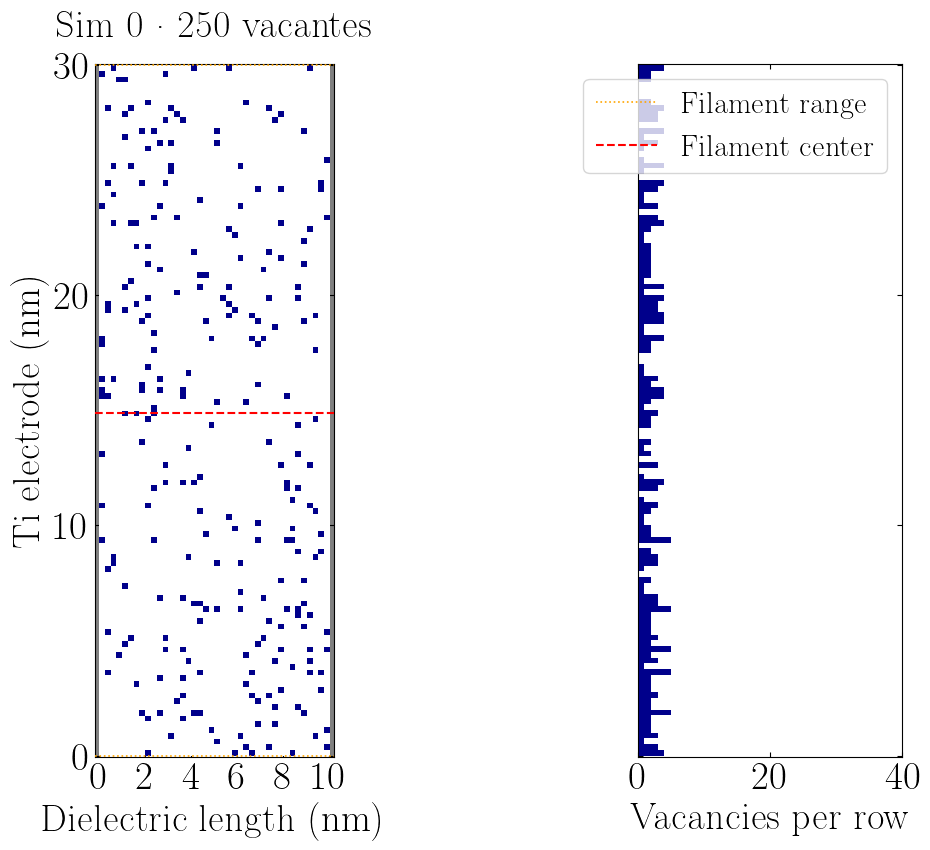

In [61]:
SIM_VER = SIMULACIONES[0]   # índice 0-based de la simulación a representar

estado = estados[SIM_VER]
cfg_ver = load_simulation_config(num_simulation=SIM_VER, init_data_dir=INIT_DATA_DIR)
atom_nm = cfg_ver.params.atom_size * 1e9

setup_paper_plt(plt, latex=True, scaling=2)
fig, (ax, ax_perfil) = plt.subplots(
    1, 2, figsize=(14, 9), gridspec_kw={"width_ratios": [3, 1], "wspace": 0.05}, sharey=True
)

size_x_nm, size_y_nm = dibujar_estado(ax, estado, cfg_ver.params.atom_size)

# Filamentos: filas -> nm (centro de la celda; origen abajo, como en la matriz dibujada)
for k, (row_min, row_max) in enumerate(cfg_ver.cf_ranges):
    ax.axhline(row_min * atom_nm, color="orange", linewidth=1.2, linestyle=":",
               label="Filament range" if k == 0 else None, zorder=3)
    ax.axhline((row_max + 1) * atom_nm, color="orange", linewidth=1.2, linestyle=":", zorder=3)
for k, centro in enumerate(cfg_ver.cf_centros):
    ax.axhline((centro + 0.5) * atom_nm, color="red", linewidth=1.5, linestyle="--",
               label="Filament center" if k == 0 else None, zorder=3)
ax.set_title(rf"Sim {SIM_VER} · {int(estado.sum())} vacantes", pad=20)

# Perfil: vacantes por fila, alineado con el eje y en nm
config_ax_state(ax_perfil)
ax_perfil.barh((np.arange(estado.shape[0]) + 0.5) * atom_nm, estado.sum(axis=1),
               height=atom_nm, color=COLOR_VACANTE, zorder=2)
ax_perfil.set_xlabel("Vacancies per row")
ax_perfil.set_xlim(0, estado.shape[1])  # máximo posible por fila = nº de columnas
ax_perfil.tick_params(labelleft=False)
ax_perfil.legend(*ax.get_legend_handles_labels(), loc="upper right")  # fuera del mapa para no tapar vacantes

plt.show()

### 5.2 · Vacantes por fila según número de vecinos

Igual que 5.1, pero cada barra se apila por colores: cuántas de las vacantes de esa fila tienen
0, 1, 2, 3 o 4 vecinos vacante directos (arriba, abajo, izquierda, derecha). Solo se cuentan
vacantes, no celdas vacías. Elige la simulación en `SIM_VER_VEC`.

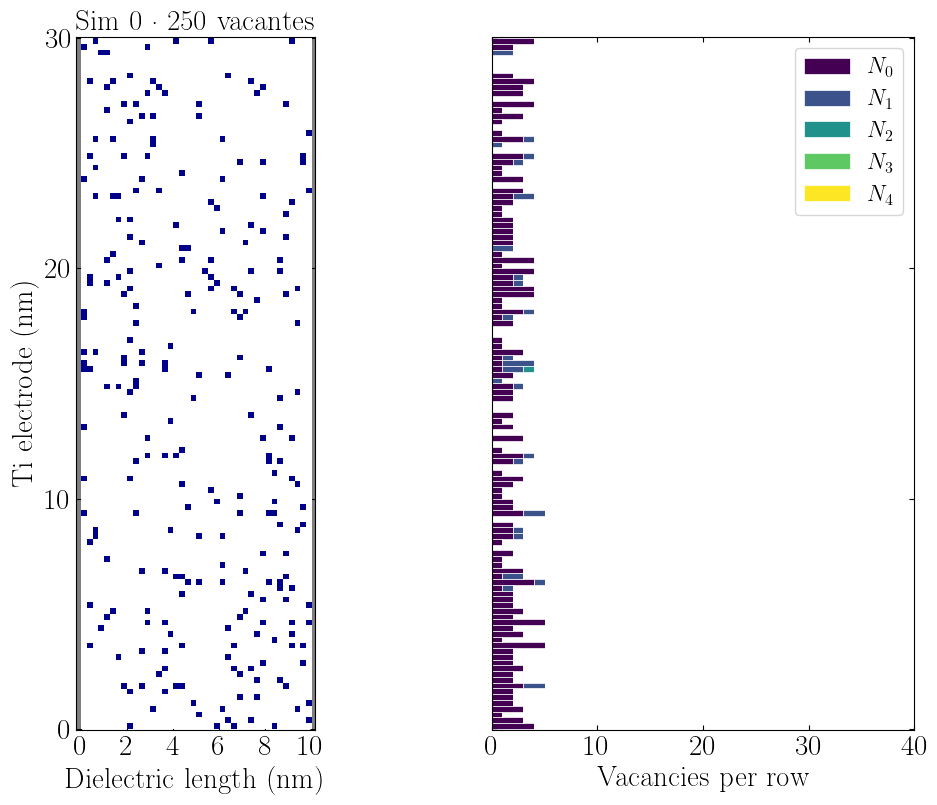

In [62]:
SIM_VER_VEC = SIMULACIONES[0]   # índice 0-based de la simulación a representar

COLORES_VECINOS = plt.cm.viridis(np.linspace(0, 1, 5))  # N_0 ... N_4, mismos tonos que las barras de la figura de referencia


def vacantes_por_fila_y_vecinos(estado: np.ndarray) -> np.ndarray:
    """Matriz (filas, 5): vacantes de cada fila con 0..4 vecinos vacante (cruz, sin diagonales)."""
    es_vacante = estado.astype(bool)
    kernel = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])
    vecinos = convolve2d(es_vacante.astype(int), kernel, mode="same", boundary="fill", fillvalue=0)
    return np.stack([((vecinos == n) & es_vacante).sum(axis=1) for n in range(5)], axis=1)


estado = estados[SIM_VER_VEC]
cfg_vec = load_simulation_config(num_simulation=SIM_VER_VEC, init_data_dir=INIT_DATA_DIR)
atom_nm = cfg_vec.params.atom_size * 1e9
conteo = vacantes_por_fila_y_vecinos(estado)
assert conteo.sum() == estado.sum()

setup_paper_plt(plt, latex=True, scaling=1.5)
fig, (ax, ax_perfil) = plt.subplots(
    1, 2, figsize=(12, 9), gridspec_kw={"width_ratios": [1, 1]}, sharey=True
)

dibujar_estado(ax, estado, cfg_vec.params.atom_size)
ax.set_title(rf"Sim {SIM_VER_VEC} · {int(estado.sum())} vacantes", pad=5)

config_ax_state(ax_perfil)
y = (np.arange(estado.shape[0]) + 0.5) * atom_nm
izquierda = np.zeros(estado.shape[0])
for n in range(5):
    ax_perfil.barh(y, conteo[:, n], left=izquierda, height=atom_nm, color=COLORES_VECINOS[n],
                   edgecolor="white", linewidth=0.5, label=rf"$N_{n}$", zorder=2)
    izquierda += conteo[:, n]
ax_perfil.set_xlabel("Vacancies per row")
ax_perfil.set_xlim(0, estado.shape[1])  # máximo posible por fila = nº de columnas
ax_perfil.tick_params(labelleft=False)
ax_perfil.legend(loc="upper right")

plt.show()

## 6 · Verificación opcional

`Percolation.is_path` indica si el estado ya conecta los electrodos. Para PP_set lo normal es
que **no** percole al principio (la formación del filamento es justo lo que se simula).

In [63]:
for i, estado in estados.items():
    print(f"Sim {i}: percola = {Percolation.is_path(estado)}")

Sim 0: percola = False
Sim 1: percola = False
Sim 2: percola = False
Sim 3: percola = False
Sim 4: percola = False
Sim 5: percola = False
Sim 6: percola = False
Sim 7: percola = False
Sim 8: percola = False
Sim 9: percola = False


## 7 · Utilidad: vecindad de las vacantes

In [64]:
def contar_vecindad(actual_state, valor_vacante=1, verbose=False):
    """
    Cuenta cuántas celdas tienen exactamente 0, 1, 2, 3 o 4 vecinos vacante directos
    (arriba, abajo, izquierda, derecha).

    Retorna: [con_0, con_1, con_2, con_3, con_4]
    """
    es_vacante = (np.array(actual_state) == valor_vacante).astype(int)
    kernel = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])
    conteo_vecinos = convolve2d(es_vacante, kernel, mode="same", boundary="fill", fillvalue=0)
    if verbose:
        print("Conteo de vecinos para cada celda:\n", conteo_vecinos)

    resultados = []
    for n in range(5):
        cantidad = int(np.sum(conteo_vecinos == n))
        print(cantidad, f"celdas con {n} vecinos vacante")
        resultados.append(cantidad)
    return resultados


for i, estado in estados.items():
    print(f"Sim {i}:")
    contar_vecindad(estado)

Sim 0:
3900 celdas con 0 vecinos vacante
826 celdas con 1 vecinos vacante
72 celdas con 2 vecinos vacante
2 celdas con 3 vecinos vacante
0 celdas con 4 vecinos vacante
Sim 1:
3895 celdas con 0 vecinos vacante
826 celdas con 1 vecinos vacante
77 celdas con 2 vecinos vacante
2 celdas con 3 vecinos vacante
0 celdas con 4 vecinos vacante
Sim 2:
3905 celdas con 0 vecinos vacante
812 celdas con 1 vecinos vacante
79 celdas con 2 vecinos vacante
4 celdas con 3 vecinos vacante
0 celdas con 4 vecinos vacante
Sim 3:
3896 celdas con 0 vecinos vacante
826 celdas con 1 vecinos vacante
75 celdas con 2 vecinos vacante
3 celdas con 3 vecinos vacante
0 celdas con 4 vecinos vacante
Sim 4:
3889 celdas con 0 vecinos vacante
843 celdas con 1 vecinos vacante
67 celdas con 2 vecinos vacante
1 celdas con 3 vecinos vacante
0 celdas con 4 vecinos vacante
Sim 5:
3860 celdas con 0 vecinos vacante
893 celdas con 1 vecinos vacante
46 celdas con 2 vecinos vacante
1 celdas con 3 vecinos vacante
0 celdas con 4 vecinos 